# **Lab session 1**
## **Exercise 2 : Recognition of hand-written characters from the scikit-learn database using a perceptron**

In this exercise you are to implement a simple hand-written digit classifier based on a perceptron (no convolutional networks). 

**This assignment contains examples of results you should reproduce with your code.**

In [57]:
# Import the scikit-learn digits dataset
import pandas as pd
from sklearn import datasets

digits = datasets.load_digits()

# Type de l'objet
print(type(digits)) 

# Attributs disponibles
print(digits.keys())


<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])


The data we are interested in are 8x8 images of digits. They are stored in the `images` attribute of the dataset. 

Have a look at the data and the classes: 

1.   For every image, we know which digit it represents. It is the  'target' of the dataset.
2.   Show the first 10 images and their target.



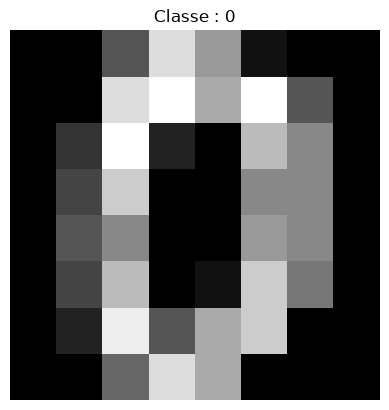

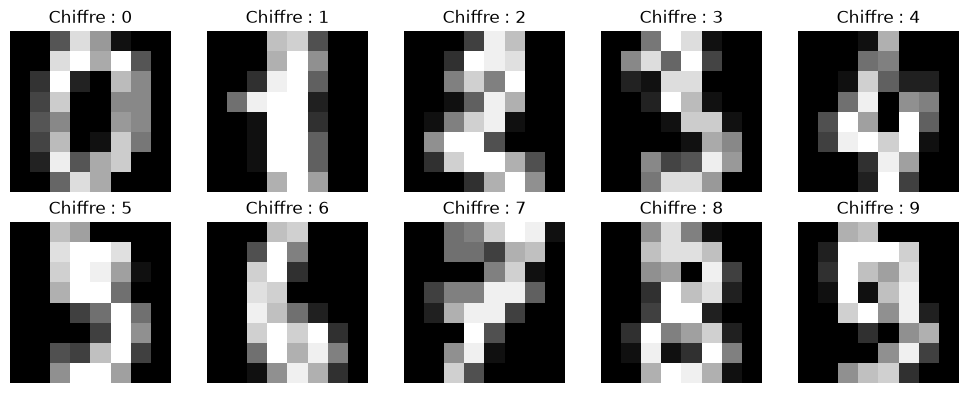

In [58]:
import matplotlib.pyplot as plt

plt.imshow(digits.images[0], cmap="gray")
plt.title(f"Classe : {digits.target[0]}")
plt.axis("off")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Chiffre : {digits.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

To apply a perceptron classifier on this data, we will not use 8x8 images but the vectorized version stored in digits.data.

1. How many images do we have in the dataset?
2. How many classes do we have in the dataset?
3. What is the size of the vector representing the flattened version of the images?

In [59]:
print(f"""In the dataset, we have {digits.data.shape[0]} images with {digits.data.shape[1]} features each.""")
print(f"We have  {len(digits.target_names)} classes in the dataset.")
print(f"The size of the vector representing the flattened version of the images is {digits.data.shape[1]}.")

In the dataset, we have 1797 images with 64 features each.
We have  10 classes in the dataset.
The size of the vector representing the flattened version of the images is 64.


How many classes do we have? 

In [60]:
print(f"We have  {len(digits.target_names)} classes in the dataset.")

We have  10 classes in the dataset.


Convert the target into the matrix 'y' in one-hot format.
This will allow the predictors output one at a time using the soft-max activation. What is the shape of the 'y' matrix. Use the keras function **utils.to_categorical()**.

In [61]:
from tensorflow.keras import utils

y= utils.to_categorical(digits.target, num_classes=len(digits.target_names))
print(f"The shape of the one-hot encoded labels is {y.shape}.")

The shape of the one-hot encoded labels is (1797, 10).


## Prepare the train and test dataset.

1.   split dataset into test and train dataset.
2.   split further the train dataset into train and validation part
Use the **keras.model_selection** function **train_test_split()** to separate a dataset. You can choose the percentage of the split, or leave the defaut value.

In [62]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(digits.data, y, test_size=0.2, random_state=42)

## create the sequential model

1.   The model will the keras sequential model containing the one-layer perceptron. 
Instantiate the model using **model=Sequential()**, then add a **Dense()** layer from **keras.layers**. Adding layers can be done using the model's class function **model.add()**.
Specify the input shape, and the number of classes to output. What kind of activation will you use?
2.   Compile the model. Specify the loss. Choose an optimizer and the evaluation metrics to use. Use the class function **compile()** of the sequential model you have created.



In [63]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()

model.add(Dense(
    units=10,
    input_shape=(64,),
    activation="softmax"
))

/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## train the model

You need to specify the size of the batch and the number of epochs to train. You need to provide the training and the validation data.

Use the sequential model's class function **fit()** to train the model.

In [64]:
# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    digits.data,
    y,
    test_size=0.2,
    random_state=42,
    stratify=digits.target)

In [65]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_data=(X_val, y_val)
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1329 - loss: 7.5696 - val_accuracy: 0.1500 - val_loss: 4.9270
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step - accuracy: 0.2853 - loss: 3.9565 - val_accuracy: 0.3583 - val_loss: 2.8061
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 914us/step - accuracy: 0.4607 - loss: 2.4400 - val_accuracy: 0.5444 - val_loss: 1.8082
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 881us/step - accuracy: 0.5873 - loss: 1.6732 - val_accuracy: 0.6306 - val_loss: 1.3012
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 865us/step - accuracy: 0.6778 - loss: 1.2401 - val_accuracy: 0.6944 - val_loss: 0.9748
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 873us/step - accuracy: 0.7335 - loss: 0.9788 - val_accuracy: 0.7722 - val_loss: 0.7884
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 915us/step - accuracy: 0.7836 - loss: 0.8020 - val_accuracy: 0.7917 - val_loss: 0.6499
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 860us/step - accuracy: 0.8038 - loss: 0.6756 - val_accuracy: 0.82

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


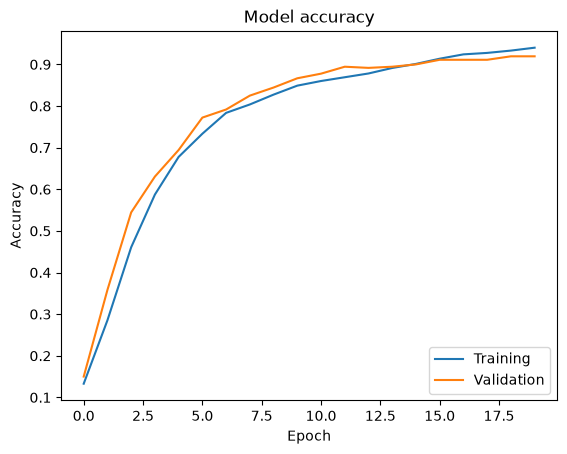

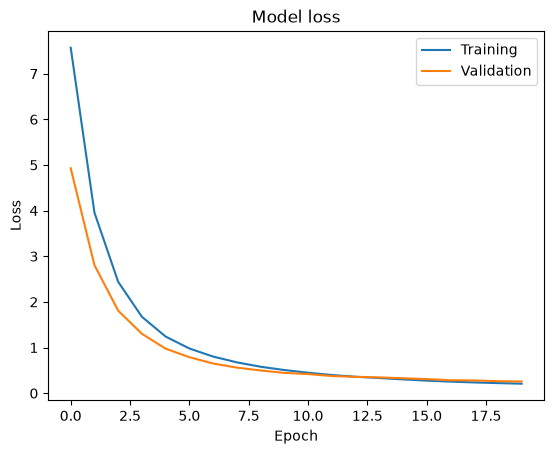

In [66]:
print(history.history.keys())
import matplotlib.pyplot as plt

# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Model accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(["Training", "Validation"], loc="lower right")
plt.show()

# loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title("Model loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["Training", "Validation"], loc="upper right")
plt.show()



## Analyze the results.

1.   Print a summary of the model - use the model's class function **summary()**. How many parameters does the model have? Is a big or a small model?
2.   What was the accuracy we obtained at the end of the training? Do you use the training or validation accuracy to answer?
3. If you run the model several times, do you always obtain the same accuracy? 

In [67]:
model.summary()
print(f"""The model have {model.count_params()} parameters
It is therefore a small model""")
print(f"Validation accuracy: {history.history['val_accuracy'][-1]}")
print(f"""We don't obtain the same accuracy when running the code multiple times because the model is initialized with
random weights. Each time you run the code, the model starts with different initial weights,  
which can lead to variations in the training process and the final accuracy achieved on the validation set.""")

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,952 (7.63 KB)

 Trainable params: 650 (2.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,302 (5.09 KB)

The model have 650 parameters
It is therefore a small model
Validation accuracy: 0.9194444417953491
We don't obtain the same accuracy when running the code multiple times because the model is initialized with
random weights. Each time you run the code, the model starts with different initial weights,  
which can lead to variations in the training process and the final accuracy achieved on the validation set.


## print the confusion matrix obtained on the test dataset.

Use the **confusion_matrix()** function provided in **sklearn.metrics**.

In [68]:

from sklearn.metrics import confusion_matrix
import numpy as np

# Probabilités prédites par le modèle
Y_pred_proba = model.predict(X_test, verbose=0)

# Classe prédite et vraie classe
Y_pred = np.argmax(Y_pred_proba, axis=1)
Y_true = np.argmax(y_test, axis=1)

# Matrice de confusion
cm = confusion_matrix(Y_true, Y_pred)

print(cm)

[[32  0  0  0  0  0  0  0  1  0]
 [ 0 26  1  0  0  0  0  0  1  0]
 [ 0  0 30  2  0  0  1  0  0  0]
 [ 0  0  0 33  0  1  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 45  1  0  0  1]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  3  1  0  1  1  0  0 24  0]
 [ 0  0  1  0  1  1  0  1  1 35]]


Normalize the confusion matrix to show graphically the prediction probability map.

Hint: The confusion matrix needs to be normalized by the counts of each class. Print the counts of elements in each class in the test dataset. Use the numpy function **unique()** to count the elements in y_test.

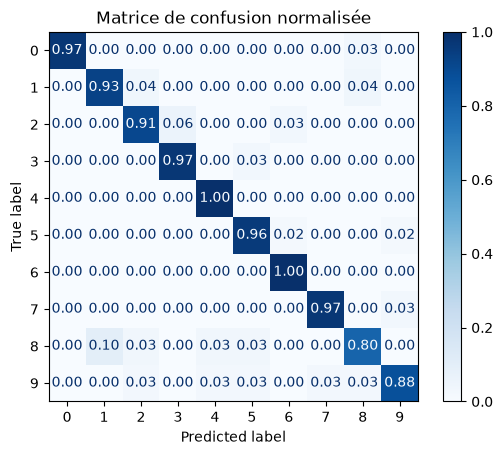

In [69]:
cm_normalized = confusion_matrix(
    Y_true,
    Y_pred,
    normalize="true"
)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


disp = ConfusionMatrixDisplay(
   confusion_matrix=cm_normalized,
   display_labels=digits.target_names
)

disp.plot(cmap="Blues", values_format=".2f")
plt.title("Matrice de confusion normalisée")
plt.show()

Evaluate the model on the test dataset. What is the accuracy on the test dataset? Use the model's class function **evaluate()**.

In [70]:

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Test loss: 0.1868058741092682
Test accuracy: 0.9416666626930237


## **Conclusions:**
Conclude your report by answering the following questions:

1. Did your training converge? 
2. Was the training successful? 
3. Do you always obtain the same accuracy when you run the code several times? 
4. Do all classes always predict with the same accuracy? 
5. Are there classes where the prediction happens to fail?

## Answers

In [71]:

print("1. The training converged; the loss decreased and the accuracy stabilized.")

print("2. The training was successful; the model obtained a high accuracy on the test data.")

print("3. We don't always get the same accuracy. The accuracy can vary slightly between runs.")

print("4.Some classes are recognized more accurately than others.")

print("5. Yes, especially classes 8 and 9, which are sometimes confused with other digits.")

1. The training converged; the loss decreased and the accuracy stabilized.
2. The training was successful; the model obtained a high accuracy on the test data.
3. We don't always get the same accuracy. The accuracy can vary slightly between runs.
4.Some classes are recognized more accurately than others.
5. Yes, especially classes 8 and 9, which are sometimes confused with other digits.
